In [1949]:
import warnings
warnings.filterwarnings('ignore') 

In [1950]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import scipy.cluster.hierarchy as sch
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller


In [1951]:
df = pd.read_csv('dublinbike-historical-data-2022-11.csv')

In [1952]:
# Display the first five records
df.head()

,STATION ID,TIME,LAST UPDATED,NAME,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,STATUS,ADDRESS,LATITUDE,LONGITUDE
0,1,2022-11-01 00:00:03,2022-10-31 23:51:25,CLARENDON ROW,31,9,22,OPEN,Clarendon Row,53.3409,-6.26250
1,2,2022-11-01 00:00:03,2022-10-31 23:53:48,BLESSINGTON STREET,20,15,5,OPEN,Blessington Street,53.3568,-6.26814
2,3,2022-11-01 00:00:03,2022-10-31 23:50:25,BOLTON STREET,20,17,3,OPEN,Bolton Street,53.3512,-6.26986
3,4,2022-11-01 00:00:03,2022-10-31 23:58:06,GREEK STREET,20,0,20,OPEN,Greek Street,53.3469,-6.27298
4,5,2022-11-01 00:00:03,2022-10-31 23:50:27,CHARLEMONT PLACE,40,31,9,OPEN,Charlemont Street,53.3307,-6.26018


In [1953]:
# Display the last five records
df.tail()

,STATION ID,TIME,LAST UPDATED,NAME,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,STATUS,ADDRESS,LATITUDE,LONGITUDE
162602,113,2022-11-30 23:30:02,2022-11-30 23:26:00,MERRION SQUARE SOUTH,40,15,25,OPEN,Merrion Square South,53.3386,-6.24861
162603,114,2022-11-30 23:30:02,2022-11-30 23:26:47,WILTON TERRACE (PARK),40,40,0,OPEN,Wilton Terrace (Park),53.3337,-6.24834
162604,115,2022-11-30 23:30:02,2022-11-30 23:23:32,KILLARNEY STREET,30,5,25,OPEN,Killarney Street,53.3548,-6.24758
162605,116,2022-11-30 23:30:02,2022-11-30 23:25:26,BROADSTONE,30,28,2,OPEN,Broadstone,53.3547,-6.27231
162606,117,2022-11-30 23:30:02,2022-11-30 23:22:24,HANOVER QUAY EAST,40,30,10,OPEN,Hanover Quay East,53.3437,-6.23175


In [1954]:
# Number of rows and columns
print("Dataset shape:", df.shape)

Dataset shape: (162607, 11)


In [1955]:
# Data type and non nul values of each colun
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 162607 entries, 0 to 162606
Data columns (total 11 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   STATION ID             162607 non-null  int64  
 1   TIME                   162607 non-null  str    
 2   LAST UPDATED           162607 non-null  str    
 3   NAME                   162607 non-null  str    
 4   BIKE_STANDS            162607 non-null  int64  
 5   AVAILABLE_BIKE_STANDS  162607 non-null  int64  
 6   AVAILABLE_BIKES        162607 non-null  int64  
 7   STATUS                 162607 non-null  str    
 8   ADDRESS                162607 non-null  str    
 9   LATITUDE               162607 non-null  float64
 10  LONGITUDE              162607 non-null  float64
dtypes: float64(2), int64(4), str(5)
memory usage: 25.3 MB


In [1956]:
# Descriptive statistic of the numerical column
df.describe()

,STATION ID,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,LATITUDE,LONGITUDE
count,162607.000000,162607.000000,162607.000000,162607.000000,162607.000000,162607.000000
mean,58.699115,32.000000,19.783503,11.987965,53.345591,-6.264277
std,34.239989,7.488067,11.218428,9.896961,0.007600,0.017951
min,1.000000,16.000000,0.000000,0.000000,53.330100,-6.310020
25%,29.000000,29.000000,11.000000,3.000000,53.339800,-6.275070
50%,58.000000,30.000000,20.000000,10.000000,53.345200,-6.262980
75%,89.000000,40.000000,29.000000,18.000000,53.350900,-6.251560
max,117.000000,40.000000,40.000000,40.000000,53.360000,-6.230850


In [1957]:
# Number of unique value in each column
df.nunique()

STATION ID                  113
TIME                       1439
LAST UPDATED             132190
NAME                        113
BIKE_STANDS                  17
AVAILABLE_BIKE_STANDS        41
AVAILABLE_BIKES              41
STATUS                        1
ADDRESS                     113
LATITUDE                     98
LONGITUDE                   113
dtype: int64

In this dataset there is  162,607 rows and 11 columns. Each row is snapshot of one station at one moment in time: the number of stand BIKE_STANDS), the number of bike available AVAILABLE_BIKES) and the number of free stands AVAILABLE_BIKE_STANDS), together with the station name, address, status and coordinates, there are 113 station and 1,439 diferent read times (about every 30 minutes dure the 30 days of November 2022).

## Step 3: Data cleaning
I check miss values, duplicate, constant or redundant columns and the consistency of the read.

In [1958]:
# Check the miss values in each column
df.isnull().sum()

STATION ID               0
TIME                     0
LAST UPDATED             0
NAME                     0
BIKE_STANDS              0
AVAILABLE_BIKE_STANDS    0
AVAILABLE_BIKES          0
STATUS                   0
ADDRESS                  0
LATITUDE                 0
LONGITUDE                0
dtype: int64

In [1959]:
# Check the duplicate rows and duplicate station/time readings
print("Duplicated rows:", df.duplicated().sum())
print("Duplicated station/time readings:", df.duplicated(subset = ['STATION ID', 'TIME']).sum())

Duplicated rows: 0
Duplicated station/time readings: 0


In [1960]:
# Checking the value of the column status
df['STATUS'].value_counts()

STATUS
OPEN    162607
Name: count, dtype: int64

In [1961]:
# Check if the column adress give the same information as the column name
print("Unique names:", df['NAME'].nunique())
print("Unique addresses:", df['ADDRESS'].nunique())

Unique names: 113
Unique addresses: 113


- There are no miss values and no duplicated readings.
- Status have only one value opem), so it is a constant column and give no information to the models.
- Address has the same number of unique values as name (one per station), so it is redundant.
- Last update  is a technical timestamp of the API (when the station last communicated) and is not needed, because we use time as the reading time.
These three columns are removed.

In [1962]:
# Drop the constant and redundant columns
df = df.drop(['STATUS', 'ADDRESS', 'LAST UPDATED'], axis = 1)

# Convert the column TIME into datetime format
df['TIME'] = pd.to_datetime(df['TIME'])

# Sort the readings by station and time
df = df.sort_values(['STATION ID', 'TIME']).reset_index(drop = True)

# Display the first five records
df.head()

,STATION ID,TIME,NAME,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,LATITUDE,LONGITUDE
0,1,2022-11-01 00:00:03,CLARENDON ROW,31,9,22,53.3409,-6.2625
1,1,2022-11-01 00:30:02,CLARENDON ROW,31,9,22,53.3409,-6.2625
2,1,2022-11-01 01:00:03,CLARENDON ROW,31,9,22,53.3409,-6.2625
3,1,2022-11-01 01:30:03,CLARENDON ROW,31,9,22,53.3409,-6.2625
4,1,2022-11-01 02:00:04,CLARENDON ROW,31,9,22,53.3409,-6.2625


In [1963]:
# Consistency check: bikes + free stand should be equal to the total number of stands
df['STANDS_CHECK'] = df['BIKE_STANDS'] - (df['AVAILABLE_BIKES'] + df['AVAILABLE_BIKE_STANDS'])

# Percentage of readiing where the number do not get a match
print("Readings with a difference:", round((df['STANDS_CHECK'] != 0).mean() * 100, 2), "%")
print(df['STANDS_CHECK'].describe())

Readings with a difference: 6.32 %
count    162607.000000
mean          0.228533
std           2.533585
min           0.000000
25%           0.000000
50%           0.000000
75%           0.000000
max          40.000000
Name: STANDS_CHECK, dtype: float64


In a small share of the readings the sum of bike and free stands is lower than total number of stands, this happen when some stands of bikes are temporary out of service (for example a broken dock). These are a real operational situations, not errors, so the rows are kept, for compare stations of different sizes we will use the occupancy rate (available bikes / total stands) instead absolute numbers.

In [1964]:
df = df.drop('STANDS_CHECK', axis = 1)

df['TIME_SLOT'] = df['TIME'].dt.floor('30min')

expected_slots = pd.date_range(start = '2022-11-01 00:00', end = '2022-11-30 23:30', freq = '30min')

missing_slots = expected_slots.difference(df['TIME_SLOT'].unique())
print("Expected slots:", len(expected_slots))
print("Missing slots:", len(missing_slots), list(missing_slots))

Expected slots: 1440
Missing slots: 1 [Timestamp('2022-11-04 23:00:00')]


Only one 30 minute slot is miss (4 November 2022 at 23:00) out of 1,440. This is very small gap, when we build the hourly time serie later, the change in bikes across this gap is stil captured for the next read, so no information about the total demand is lost.

In [1965]:
df['OCCUPANCY_RATE'] = df['AVAILABLE_BIKES'] / df['BIKE_STANDS']

df['ACTIVITY'] = df.groupby('STATION ID')['AVAILABLE_BIKES'].diff().abs().fillna(0)

df['HOUR'] = df['TIME'].dt.hour
df['DAY_NAME'] = df['TIME'].dt.day_name()
df['IS_WEEKEND'] = (df['TIME'].dt.dayofweek >= 5).astype(int)

df['PERIOD_OF_DAY'] = pd.cut(df['HOUR'],
                             bins = [-1, 4, 6, 9, 15, 19, 23],
                             labels = ['Overnight', 'Early morning', 'Morning peak', 'Midday', 'Evening peak', 'Night'])

df.head()

,STATION ID,TIME,NAME,BIKE_STANDS,AVAILABLE_BIKE_STANDS,AVAILABLE_BIKES,LATITUDE,LONGITUDE,TIME_SLOT,OCCUPANCY_RATE,ACTIVITY,HOUR,DAY_NAME,IS_WEEKEND,PERIOD_OF_DAY
0,1,2022-11-01 00:00:03,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 00:00:00,0.709677,0.0,0,Tuesday,0,Overnight
1,1,2022-11-01 00:30:02,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 00:30:00,0.709677,0.0,0,Tuesday,0,Overnight
2,1,2022-11-01 01:00:03,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 01:00:00,0.709677,0.0,1,Tuesday,0,Overnight
3,1,2022-11-01 01:30:03,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 01:30:00,0.709677,0.0,1,Tuesday,0,Overnight
4,1,2022-11-01 02:00:04,CLARENDON ROW,31,9,22,53.3409,-6.2625,2022-11-01 02:00:00,0.709677,0.0,2,Tuesday,0,Overnight


In [1966]:
centre_lat, centre_lon = 53.3473, -6.2591
earth_radius = 6371  # km

lat1, lon1 = np.radians(df['LATITUDE']), np.radians(df['LONGITUDE'])
lat2, lon2 = np.radians(centre_lat), np.radians(centre_lon)

a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df['DIST_CENTRE_KM'] = 2 * earth_radius * np.arcsin(np.sqrt(a))

df[['NAME', 'DIST_CENTRE_KM']].drop_duplicates().sort_values('DIST_CENTRE_KM').head()

,NAME,DIST_CENTRE_KM
46048,PRINCES STREET / O'CONNELL STREET,0.205387
31658,CUSTOM HOUSE,0.314999
30219,TOWNSEND STREET,0.336254
18707,FOWNES STREET UPPER,0.412891
21585,GEORGES QUAY,0.459218


In [1967]:
# Final structure to cleaned the dataset
print("Dataset shape after cleaning:", df.shape)
df.dtypes

Dataset shape after cleaning: (162607, 16)


STATION ID                        int64
TIME                     datetime64[us]
NAME                                str
BIKE_STANDS                       int64
AVAILABLE_BIKE_STANDS             int64
AVAILABLE_BIKES                   int64
LATITUDE                        float64
LONGITUDE                       float64
TIME_SLOT                datetime64[us]
OCCUPANCY_RATE                  float64
ACTIVITY                        float64
HOUR                              int32
DAY_NAME                            str
IS_WEEKEND                        int64
PERIOD_OF_DAY                  category
DIST_CENTRE_KM                  float64
dtype: object

Exploratory data analysis

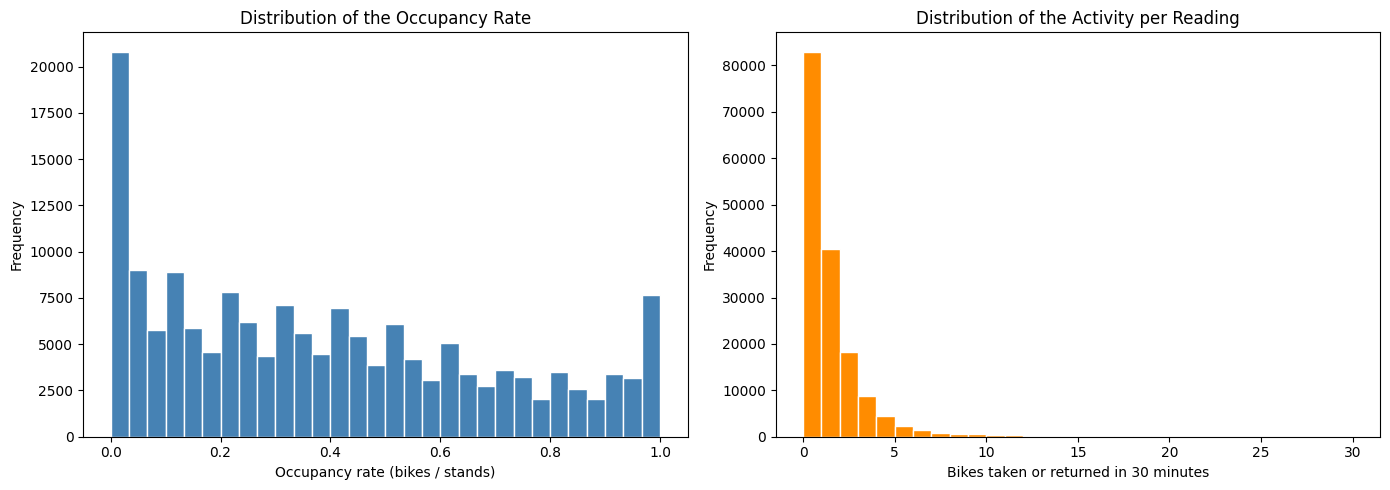

In [1968]:
# Distribution of the ocuppancy rate and of the activity
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

axes[0].hist(df['OCCUPANCY_RATE'], bins = 30, color = 'steelblue', edgecolor = 'white')
axes[0].set_title('Distribution of the Occupancy Rate')
axes[0].set_xlabel('Occupancy rate (bikes / stands)')
axes[0].set_ylabel('Frequency')

axes[1].hist(df['ACTIVITY'], bins = 30, color = 'darkorange', edgecolor = 'white')
axes[1].set_title('Distribution of the Activity per Reading')
axes[1].set_xlabel('Bikes taken or returned in 30 minutes')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

- The occupancy rate go from 0 to 1, and many readings are close to 0 (empty station). These are the most difficult situation for users.
- The activity is very right-skewed: in most 30-minute readings there are no change or only a little and only a small number of reading show a lot of movement (busy stations at peak times).

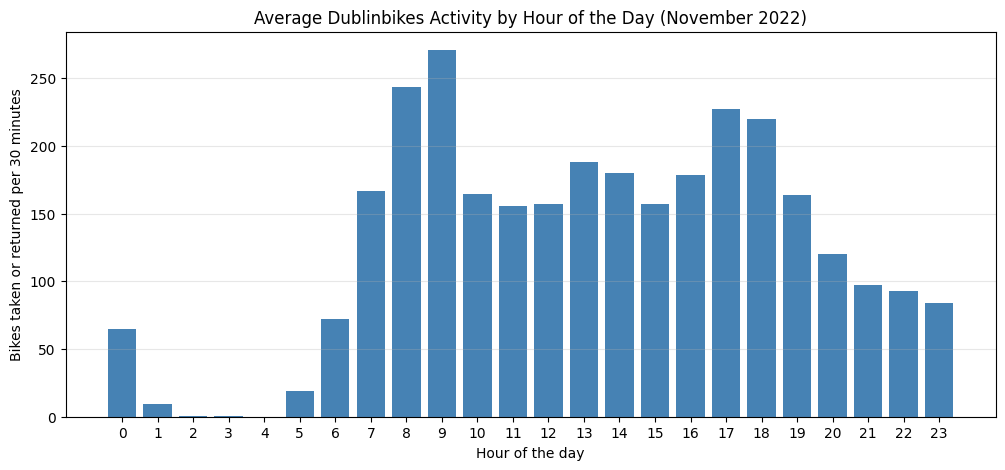

In [1969]:
# Total activity in the system in each 30-minute slot then the average for each hour day
hourly_profile = df.groupby(['TIME_SLOT', 'HOUR'])['ACTIVITY'].sum().groupby('HOUR').mean()

plt.figure(figsize = (12, 5))                                              
plt.bar(hourly_profile.index, hourly_profile.values, color = 'steelblue')  
plt.title('Average Dublinbikes Activity by Hour of the Day (November 2022)')
plt.xlabel('Hour of the day')
plt.ylabel('Bikes taken or returned per 30 minutes')
plt.xticks(range(0, 24))                                                   
plt.grid(axis = 'y', alpha = 0.3)                                          
plt.show()

The hourly profile show a clear commuter pattern: a morning peak at 08:00 - 09:00 and during the evening peak at 17:00 - 18:00. Between 01:00 and 04:00 there are almost no activity, because the system is closed at night the customers only can get the bikes from 05:00 to 00:30).

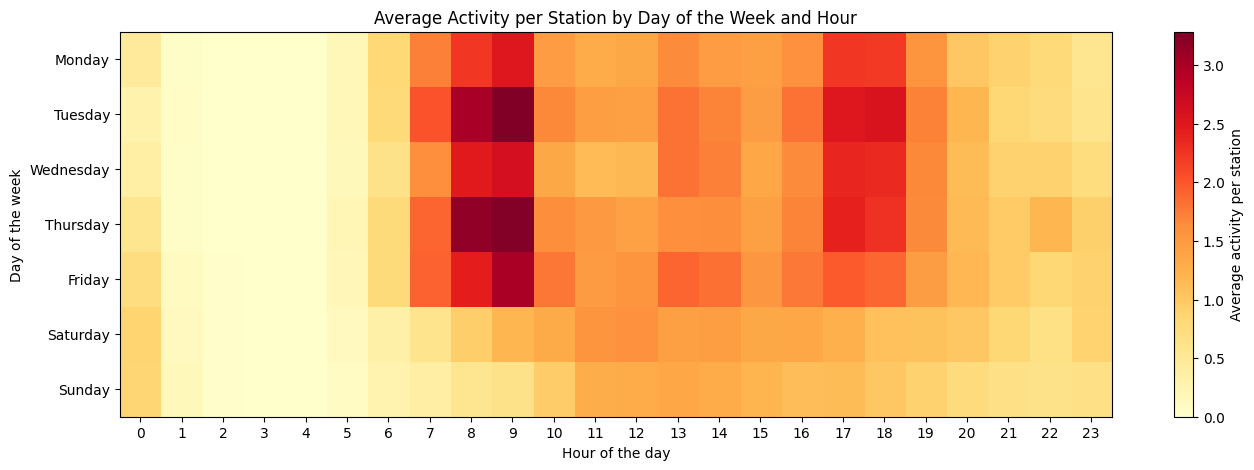

In [1970]:
# Order of the days of the week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

heatmap_data = df.pivot_table(index = 'DAY_NAME', columns = 'HOUR', values = 'ACTIVITY', aggfunc = 'mean').reindex(day_order)

# Plot the heatmap 
plt.figure(figsize = (16, 5))                                         
plt.imshow(heatmap_data.values, cmap = 'YlOrRd', aspect = 'auto')     
plt.colorbar(label = 'Average activity per station')                  
plt.xticks(range(24), heatmap_data.columns)                           
plt.yticks(range(7), heatmap_data.index)                              
plt.title('Average Activity per Station by Day of the Week and Hour')
plt.xlabel('Hour of the day')
plt.ylabel('Day of the week')
plt.show()

The heatmap show the weekdays have two clear peaks (people going to and coming back from work), while Saturdays and Sundays have only one smaler peak in the afternoon (leisure use). It can help to undertand the  difference between weekdays and weekends is important for the clusters and also for the seasonality of the time series.

In [1971]:
station_summary = df.groupby(['NAME', 'LATITUDE', 'LONGITUDE']).agg(
    AVG_ACTIVITY = ('ACTIVITY', 'mean'),           
    AVG_OCCUPANCY = ('OCCUPANCY_RATE', 'mean'),    
    BIKE_STANDS = ('BIKE_STANDS', 'first')).reset_index()   

# Top 10 busiest stations
station_summary.sort_values('AVG_ACTIVITY', ascending = False).head(10)

,NAME,LATITUDE,LONGITUDE,AVG_ACTIVITY,AVG_OCCUPANCY,BIKE_STANDS
36,GRAND CANAL DOCK,53.3426,-6.23870,2.258513,0.367981,40
91,PRINCES STREET / O'CONNELL STREET,53.3490,-6.26031,2.240445,0.641206,23
77,MOUNTJOY SQUARE WEST,53.3563,-6.25859,2.235580,0.415404,30
9,CHARLEMONT PLACE,53.3307,-6.26018,2.166088,0.466887,40
96,SIR PATRICK DUN'S,53.3392,-6.24064,2.159138,0.329743,40
26,EXCHEQUER STREET,53.3430,-6.26358,2.029187,0.546242,24
89,PORTOBELLO HARBOUR,53.3304,-6.26516,2.015288,0.486912,30
44,HANOVER QUAY,53.3441,-6.23715,1.822794,0.330629,40
87,PEARSE STREET,53.3443,-6.25043,1.818624,0.373685,30
78,NEW CENTRAL BANK,53.3471,-6.23475,1.813065,0.350956,40


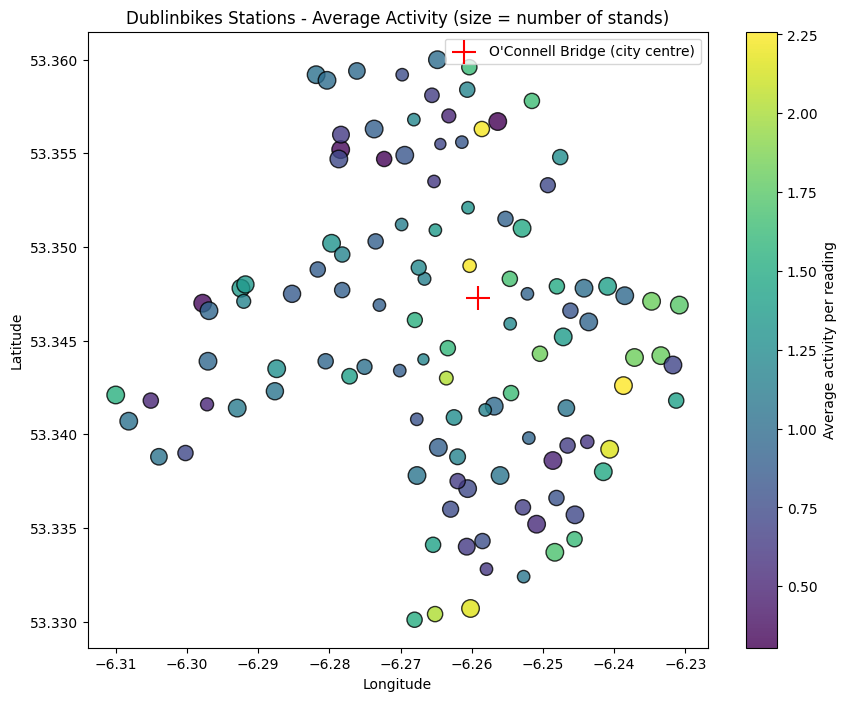

In [1972]:
plt.figure(figsize = (10, 8))

plt.scatter(station_summary['LONGITUDE'], station_summary['LATITUDE'],
            c = station_summary['AVG_ACTIVITY'], s = station_summary['BIKE_STANDS'] * 4,
            cmap = 'viridis', alpha = 0.8, edgecolors = 'black')
plt.colorbar(label = 'Average activity per reading')   # Colour scale

plt.scatter(centre_lon, centre_lat, c = 'red', marker = '+', s = 300, label = "O'Connell Bridge (city centre)")

plt.title('Dublinbikes Stations - Average Activity (size = number of stands)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.show()

The busiest stations are in the city centre and the Docklands (business area), stations in the west (Kilmainham, Heuston) and in the north of the city there are less activity.

In [1973]:
df_service = df[df['HOUR'].between(5, 23)]

# Build one profile for each station, hour and type of day
profiles = df_service.groupby(['STATION ID', 'NAME', 'HOUR', 'IS_WEEKEND']).agg(
    AVG_OCCUPANCY = ('OCCUPANCY_RATE', 'mean'),     
    OCCUPANCY_STD = ('OCCUPANCY_RATE', 'std'),       
    AVG_ACTIVITY = ('ACTIVITY', 'mean'),             
    BIKE_STANDS = ('BIKE_STANDS', 'first'),          
    DIST_CENTRE_KM = ('DIST_CENTRE_KM', 'first'),    
    LATITUDE = ('LATITUDE', 'first'),
    LONGITUDE = ('LONGITUDE', 'first')).reset_index()

# Add the categorical variables for the interpretation
profiles['DAY_TYPE'] = np.where(profiles['IS_WEEKEND'] == 1, 'Weekend', 'Weekday')
profiles['PERIOD_OF_DAY'] = pd.cut(profiles['HOUR'],
                                   bins = [4, 6, 9, 15, 19, 23],
                                   labels = ['Early morning', 'Morning peak', 'Midday', 'Evening peak', 'Night'])

print("Profiles shape:", profiles.shape)
profiles.head()

Profiles shape: (4294, 13)


,STATION ID,NAME,HOUR,IS_WEEKEND,AVG_OCCUPANCY,OCCUPANCY_STD,AVG_ACTIVITY,BIKE_STANDS,DIST_CENTRE_KM,LATITUDE,LONGITUDE,DAY_TYPE,PERIOD_OF_DAY
0,1,CLARENDON ROW,5,0,0.247801,0.276251,0.000000,31,0.746583,53.3409,-6.2625,Weekday,Early morning
1,1,CLARENDON ROW,5,1,0.568548,0.275204,0.000000,31,0.746583,53.3409,-6.2625,Weekend,Early morning
2,1,CLARENDON ROW,6,0,0.260997,0.273968,0.886364,31,0.746583,53.3409,-6.2625,Weekday,Early morning
3,1,CLARENDON ROW,6,1,0.604839,0.261668,0.625000,31,0.746583,53.3409,-6.2625,Weekend,Early morning
4,1,CLARENDON ROW,7,0,0.327713,0.256649,1.409091,31,0.746583,53.3409,-6.2625,Weekday,Morning peak


In [1974]:
features = ['AVG_OCCUPANCY', 'OCCUPANCY_STD', 'AVG_ACTIVITY', 'BIKE_STANDS', 'DIST_CENTRE_KM']
profiles[features].describe()

,AVG_OCCUPANCY,OCCUPANCY_STD,AVG_ACTIVITY,BIKE_STANDS,DIST_CENTRE_KM
count,4294.000000,4294.000000,4294.000000,4294.000000,4294.000000
mean,0.383662,0.200883,1.242126,32.000000,1.366219
std,0.223703,0.070031,1.022501,7.488916,0.649399
min,0.004167,0.010078,0.000000,16.000000,0.205387
25%,0.205121,0.154623,0.545455,29.000000,0.935458
50%,0.340767,0.202517,1.062500,30.000000,1.282634
75%,0.540909,0.250009,1.659091,40.000000,1.672485
max,0.993636,0.419076,10.295455,40.000000,3.429335


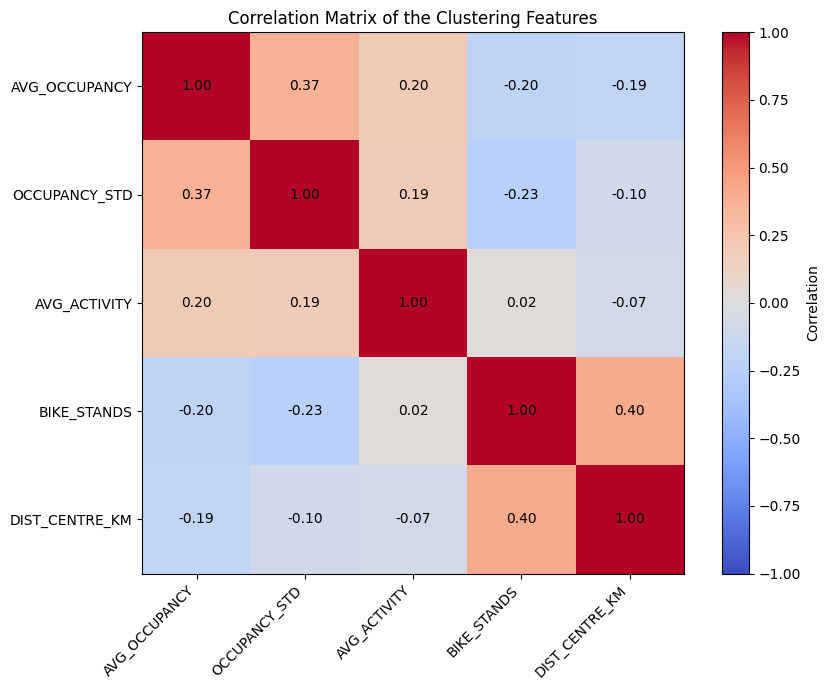

In [1975]:
corr_matrix = profiles[features].corr()

plt.figure(figsize = (9, 7))
plt.imshow(corr_matrix, cmap = 'coolwarm', vmin = -1, vmax = 1)
plt.colorbar(label = 'Correlation')

for i in range(len(features)):
    for j in range(len(features)):
        plt.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha = 'center', va = 'center')

plt.xticks(range(len(features)), features, rotation = 45, ha = 'right')
plt.yticks(range(len(features)), features)
plt.title('Correlation Matrix of the Clustering Features')
plt.tight_layout()
plt.show()

The correlation between the features are low or moderate (all lower than 0.4), so each feature gives differents information about the profile. We do not use HOUR, IS_WEEKEND and PERIOD_OF_DAY as inputs, keep them to explain the cluster later (for example, to see if a cluster happen mostly at peak hour).

The features have very different scales (occupancy from 0 to 1, stands from 16 to 40, distance in km). For this reason I standardise them with StandardScaler, so all of them have mean 0 and standard deviation 1 and have the same weight in the distance.

In [1976]:
X = profiles[features].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(X_scaled[:5])

[[-0.60739703  1.07634491 -1.21493341 -0.13354623 -0.95428002]
 [ 0.8265778   1.06139047 -1.21493341 -0.13354623 -0.95428002]
 [-0.5483992   1.0437403  -0.34797416 -0.13354623 -0.95428002]
 [ 0.98882181  0.8680907  -0.60361599 -0.13354623 -0.95428002]
 [-0.25013244  0.79640393  0.1633095  -0.13354623 -0.95428002]]


# K-Means clustering

The Sum of Squares Error (SSE) is the total squared distance between each point the centroid of it`s cluster, the best number of clusters is at the "elbow" in the graph, where the SSE stops going down a lot.

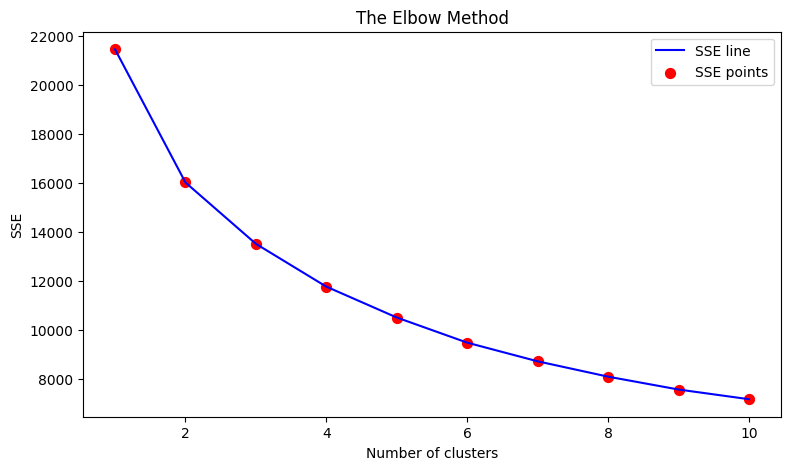

In [1977]:
sse = []  

for i in range(1, 11):
    kmeans = KMeans(n_clusters = i, max_iter = 300, n_init = 10, random_state = 42)  # Initialise an object kmeans
    kmeans.fit(X_scaled)                                                             # Training the model
    sse.append(kmeans.inertia_)                                                      # Store kmeans.inertia_ in the array sse

plt.figure(figsize = (9, 5))
plt.plot(range(1, 11), sse, linestyle = '-', color = 'blue', label = 'SSE line')
plt.scatter(range(1, 11), sse, color = 'red', marker = 'o', s = 50, label = 'SSE points')
plt.title('The Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('SSE')
plt.legend()
plt.show()

### Silhouette Score and Davies-Bouldin Index to different numbers of clusters

The elbow is not very clear, so compare the Silhouette Score (higher is better) and the Davies-Bouldin Index (lower is better) for k = 2 to 9.

In [1978]:
k_values = range(2, 10)    
silhouette_values = []     
dbi_values = []            

for n_clusters in k_values:
    kmeans = KMeans(n_clusters = n_clusters, max_iter = 300, n_init = 10, random_state = 42) 
    labels = kmeans.fit_predict(X_scaled)                           
    silhouette_values.append(silhouette_score(X_scaled, labels))   
    dbi_values.append(davies_bouldin_score(X_scaled, labels))      
    print(f"Silhouette Score (n = {n_clusters}): {silhouette_values[-1]:.4f} | Davies-Bouldin Index (n = {n_clusters}): {dbi_values[-1]:.4f}")

Silhouette Score (n = 2): 0.2438 | Davies-Bouldin Index (n = 2): 1.5865
Silhouette Score (n = 3): 0.2363 | Davies-Bouldin Index (n = 3): 1.5360
Silhouette Score (n = 4): 0.2445 | Davies-Bouldin Index (n = 4): 1.3760
Silhouette Score (n = 5): 0.2161 | Davies-Bouldin Index (n = 5): 1.4236
Silhouette Score (n = 6): 0.2209 | Davies-Bouldin Index (n = 6): 1.3388
Silhouette Score (n = 7): 0.2189 | Davies-Bouldin Index (n = 7): 1.3125
Silhouette Score (n = 8): 0.2078 | Davies-Bouldin Index (n = 8): 1.2671
Silhouette Score (n = 9): 0.2180 | Davies-Bouldin Index (n = 9): 1.2466


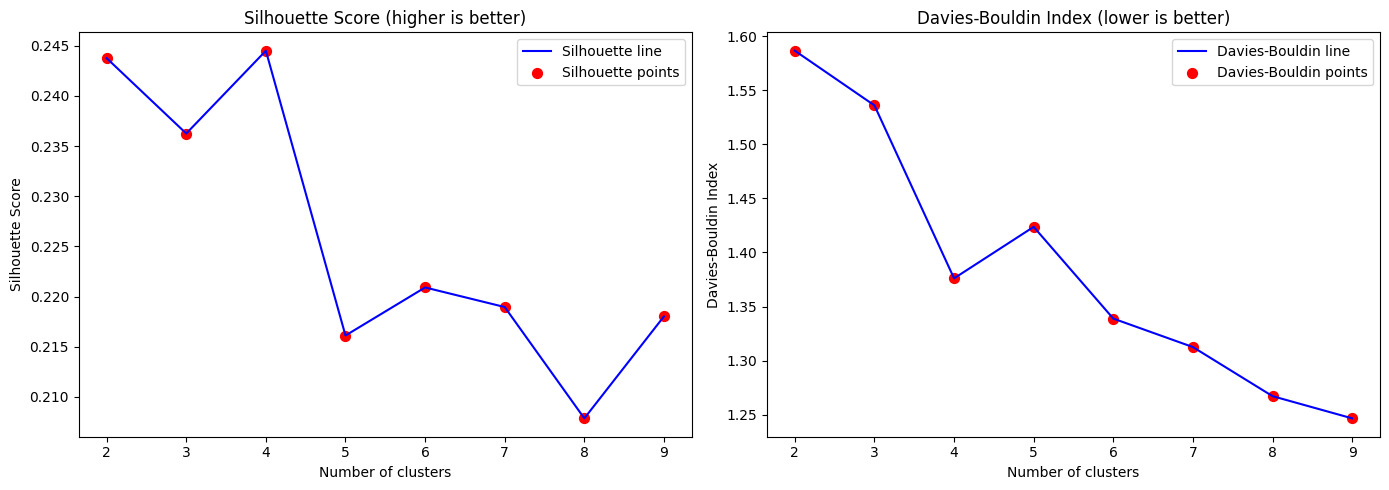

In [1979]:
fig, axes = plt.subplots(1, 2, figsize = (14, 5))

axes[0].plot(k_values, silhouette_values, linestyle = '-', color = 'blue', label = 'Silhouette line')
axes[0].scatter(k_values, silhouette_values, color = 'red', marker = 'o', s = 50, label = 'Silhouette points')
axes[0].set_title('Silhouette Score (higher is better)')
axes[0].set_xlabel('Number of clusters')
axes[0].set_ylabel('Silhouette Score')
axes[0].legend()

axes[1].plot(k_values, dbi_values, linestyle = '-', color = 'blue', label = 'Davies-Bouldin line')
axes[1].scatter(k_values, dbi_values, color = 'red', marker = 'o', s = 50, label = 'Davies-Bouldin points')
axes[1].set_title('Davies-Bouldin Index (lower is better)')
axes[1].set_xlabel('Number of clusters')
axes[1].set_ylabel('Davies-Bouldin Index')
axes[1].legend()

plt.tight_layout()
plt.show()

### Davies-Bouldin Index

To compare the clusters I also use the Davies-Bouldin Index. to calculate it with a small function, in the same way as the mape() function of the tutorials:

1. For each clusters, calculate its centroid (the mean of its points) and its spread (the average distance between of its points to the centroid).

2. For each pair of clusters, divide the sum of their spread by the distance between their centroids. A high value mean that the two clusters are wide and close to each other (bad separation).

3. For each cluster keep the highest value (its most similar cluster).

4. The Davies-Bouldin Index is the mean of these values. Lower is better.

In [1980]:
# Method to calculate the Davies-Bouldin Index
def davies_bouldin(X, labels):
    clusters = sorted(set(labels))      
    centroids = []                      
    spreads = []                        

    for k in clusters:
        points = X[labels == k]                                      
        centre = points.mean(axis = 0)                                
        distances = np.sqrt(((points - centre) * (points - centre)).sum(axis = 1))  
        centroids.append(centre)
        spreads.append(np.mean(distances))                            

    ratios = []
    for i in range(len(clusters)):
        highest = 0
        for j in range(len(clusters)):
            if i != j:
                difference = centroids[i] - centroids[j]
                distance = np.sqrt((difference * difference).sum())  
                highest = max(highest, (spreads[i] + spreads[j]) / distance)
        ratios.append(highest)

    return np.mean(ratios)

k = 4 has the highest Silhouete Score of all the options (about 0.245) and its Davies-Bouldin Index is much better than with 2 or 3 clusters, with more clusters the Davies-Bouldin Index improve only a little, but the silhouette score get worse and the clusters are harder to explain, four groups is also a practical number of station "types" for the operator. So we use k = 4.

In [1981]:
best_k = 4

kmeans = KMeans(n_clusters = best_k, max_iter = 300, n_init = 10, random_state = 42)
y_kmeans = kmeans.fit_predict(X_scaled)
profiles['KMeans_Cluster'] = y_kmeans
for k in range(best_k):
    print(f"Cluster {k}: {sum(y_kmeans == k)} profiles")

Cluster 0: 1583 profiles
Cluster 1: 441 profiles
Cluster 2: 1471 profiles
Cluster 3: 799 profiles


In [1982]:
# Centroids of the clusters in the original scale: average of the features in each cluster
centroids = profiles.groupby('KMeans_Cluster')[features].mean()

# Display the centroids
centroids

,AVG_OCCUPANCY,OCCUPANCY_STD,AVG_ACTIVITY,BIKE_STANDS,DIST_CENTRE_KM
KMeans_Cluster,,,,,
0,0.517966,0.242520,1.168762,26.258370,0.909065
1,0.449406,0.226860,3.351733,34.904762,1.359275
2,0.189489,0.140923,0.848099,34.955133,1.338038
3,0.438769,0.214440,0.948525,36.331665,2.327661


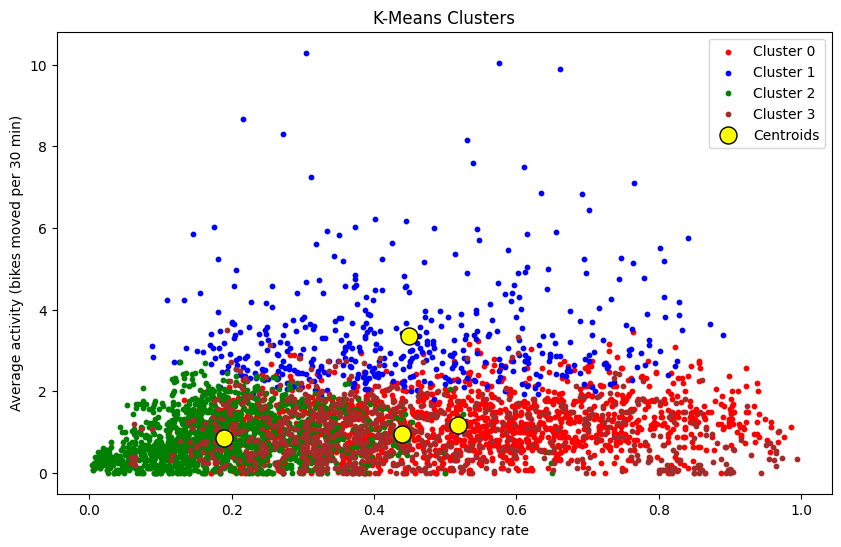

In [1983]:
# Columns used in the plot: 0 = AVG_OCCUPANCY, 2 = AVG_ACTIVITY
x = profiles[features].values

# Visualising the clusters using scatter() method
plt.figure(figsize = (10, 6))
plt.scatter(x[y_kmeans == 0, 0], x[y_kmeans == 0, 2], s = 10, c = 'red', label = 'Cluster 0')
plt.scatter(x[y_kmeans == 1, 0], x[y_kmeans == 1, 2], s = 10, c = 'blue', label = 'Cluster 1')
plt.scatter(x[y_kmeans == 2, 0], x[y_kmeans == 2, 2], s = 10, c = 'green', label = 'Cluster 2')
plt.scatter(x[y_kmeans == 3, 0], x[y_kmeans == 3, 2], s = 10, c = 'brown', label = 'Cluster 3')

# Plotting the centroids of the clusters
plt.scatter(centroids['AVG_OCCUPANCY'], centroids['AVG_ACTIVITY'], s = 150, c = 'yellow', edgecolors = 'black', label = 'Centroids')
plt.title('K-Means Clusters')
plt.xlabel('Average occupancy rate')
plt.ylabel('Average activity (bikes moved per 30 min)')

# A legend is an area describing the elements of the graph.
plt.legend(loc = 'best')
plt.show()

## Agglomerative Hierarchical clustering

### Dendrogram

The dendrogram show how the profiles are joined step by step  I use Ward linkage: at each step it join the two cluster that increasse the variance inside the cluster the least. This is the same idea as K-Means so the comparison is fair.

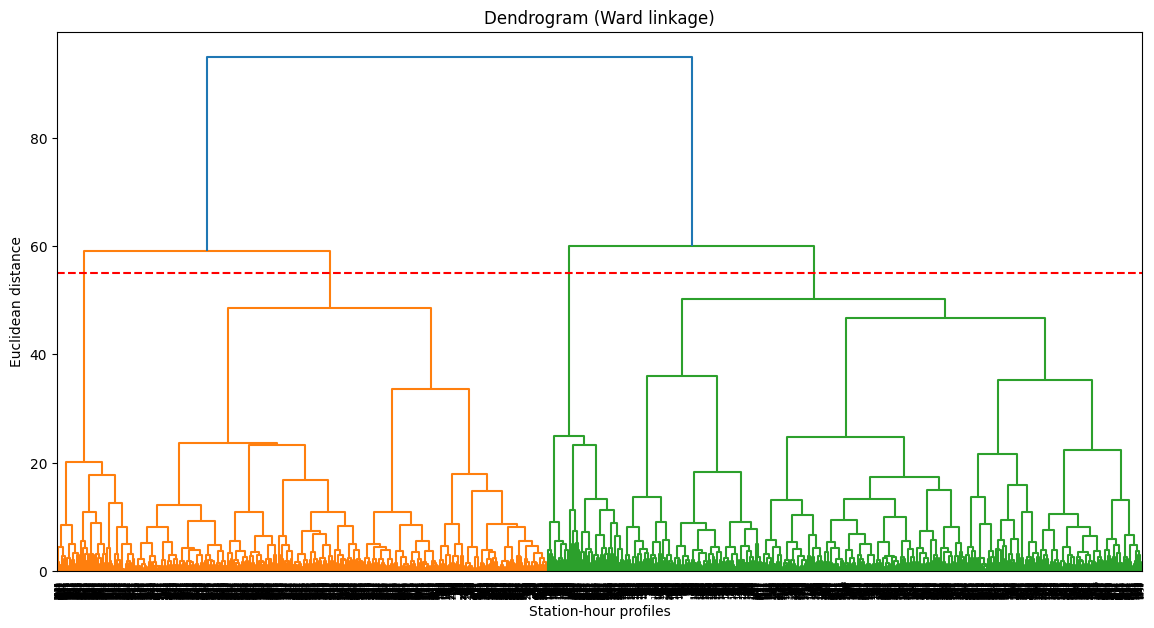

In [1984]:
plt.figure(figsize = (14, 7))

plt.title('Dendrogram (Ward linkage)')

dendrogram = sch.dendrogram(sch.linkage(X_scaled, method = 'ward'))

plt.xlabel('Station-hour profiles')
plt.ylabel('Euclidean distance')

plt.axhline(y = 55, color = 'r', linestyle = '--')
plt.show()

The longest vertical line are at the top of the dendrogram and the biggest jump in distance is the last join (2 clusters), and the next clear jump gives 4 cluster (red line). However, two or three clusters are too general for the operator (they mainly separate "more used" and "less used" profiles), I cut the dendrogram at 4 clusters because this gives more useful groups and it is the same number of clusters that we choose for K-Means. With the same k. The comparison between the two algorithms is fair.

### Choosing the linkage method

Before train the final model, compare different linkage method with 4 clusters. This shows a important limitation of the metrics.

In [1985]:
# Declare an array to store the results of each linkage method
linkage_results = []

for link in ['ward', 'complete', 'average']:
    ac_test = AgglomerativeClustering(n_clusters = best_k, metric = 'euclidean', linkage = link)  
    labels_test = ac_test.fit_predict(X_scaled)                                                   
    sizes = []                                                                                   
    for k in range(best_k):
        sizes.append(sum(labels_test == k))
    linkage_results.append([link,
                            silhouette_score(X_scaled, labels_test),        
                            davies_bouldin(X_scaled, labels_test),          
                            sizes])

pd.DataFrame(linkage_results, columns = ['Linkage', 'Silhouette Score', 'Davies-Bouldin Index', 'Cluster sizes'])

,Linkage,Silhouette Score,Davies-Bouldin Index,Cluster sizes
0,ward,0.209598,1.418370,"[2048, 1634, 302, 310]"
1,complete,0.147564,1.617099,"[1995, 76, 2212, 11]"
2,average,0.221021,1.246909,"[10, 431, 56, 3797]"


In [1986]:
# Initialise an object 'hc' by calling a method 'AgglomerativeClustering'
hc = AgglomerativeClustering(n_clusters = best_k, metric = 'euclidean', linkage = 'ward')
y_hc = hc.fit_predict(X_scaled)
profiles['Hierarchical_Cluster'] = y_hc
for k in range(best_k):
    print(f"Cluster {k}: {sum(y_hc == k)} profiles")

Cluster 0: 2048 profiles
Cluster 1: 1634 profiles
Cluster 2: 302 profiles
Cluster 3: 310 profiles


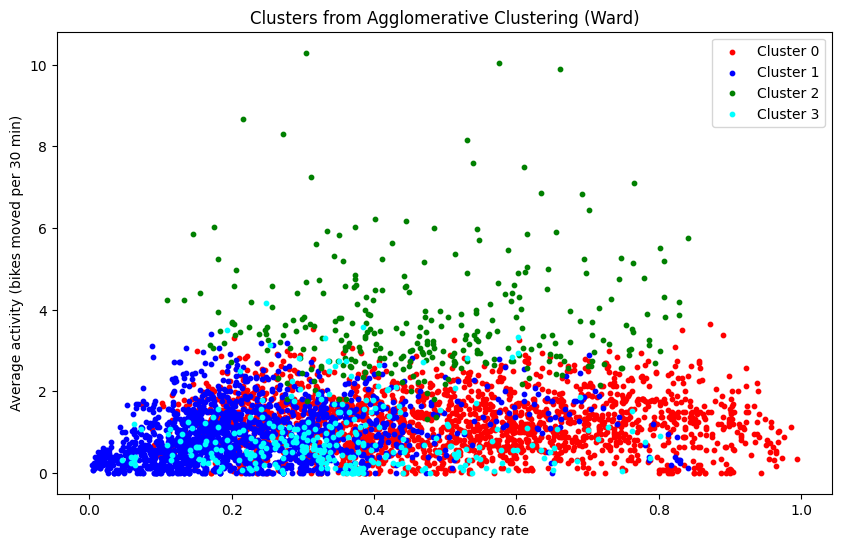

In [1987]:
# Visualising the clusters of the hierarchical
plt.figure(figsize = (10, 6))
plt.scatter(x[y_hc == 0, 0], x[y_hc == 0, 2], s = 10, c = 'red', label = 'Cluster 0')
plt.scatter(x[y_hc == 1, 0], x[y_hc == 1, 2], s = 10, c = 'blue', label = 'Cluster 1')
plt.scatter(x[y_hc == 2, 0], x[y_hc == 2, 2], s = 10, c = 'green', label = 'Cluster 2')
plt.scatter(x[y_hc == 3, 0], x[y_hc == 3, 2], s = 10, c = 'cyan', label = 'Cluster 3')
plt.title('Clusters from Agglomerative Clustering (Ward)')
plt.xlabel('Average occupancy rate')
plt.ylabel('Average activity (bikes moved per 30 min)')
plt.legend()
plt.show()

## Measuring similarity and dissimilarity between clusters

### Silhouette Score vs Davies-Bouldin Index

| | Silhouette Score | Davies-Bouldin Index |
|---|---|---|
| **What it measures** | For each point: how close it is for its own cluster (a) compared with the closest other cluster (b): s = (b - a) / max(a, b) | to each cluster: the spread inside the cluster compare to the distance between their centroids, use the most similar pair of cluster |
| **Range** | -1 to 1 | 0 to infinity |
| **Better value** | **Higher** (close to 1 = clusters well separated) | **Lower** (close to 0 = compact clusters far from each other) |
| **Level** | Each point (then the average of all points) | Each cluster (uses the centroids) |
| **Advantage** | Easy to understand; we can check each point | Fast to calculate; compares pairs of clusters directly |
| **Limitation** | Slow with big datasets (needs all the distances betwen points); prefers round clusters | Expects round clusters; only uses the centroids |

Both metrics measure similar the points are inside a cluster and how differents the clusters are from each other, but in diferent ways. Use both metrics gives a more reliable comparison than using only one.

In [1988]:
# Calculate Silhouette Scores
print("Silhouette Scores:\n")
silhouette_kmeans = silhouette_score(X_scaled, y_kmeans)       # K-Means
silhouette_hierarchical = silhouette_score(X_scaled, y_hc)     # Agglomerative
print("K-Means Clustering: ", silhouette_kmeans)
print("Agglomerative Clustering: ", silhouette_hierarchical)

# Calculate Davies-Bouldin Index
print("\nDavies-Bouldin Index:\n")
dbi_kmeans = davies_bouldin(X_scaled, y_kmeans)          # K-Means
dbi_hierarchical = davies_bouldin(X_scaled, y_hc)        # Agglomerative
print("K-Means Clustering: ", dbi_kmeans)
print("Agglomerative Clustering: ", dbi_hierarchical)

# Create dataframe with the results
clustering_results = pd.DataFrame({
    'Algorithm': ['K-Means', 'Agglomerative (Ward)'],
    'Silhouette Score': [silhouette_kmeans, silhouette_hierarchical],
    'Davies-Bouldin Index': [dbi_kmeans, dbi_hierarchical]})

# Display the results
clustering_results

Silhouette Scores:

K-Means Clustering:  0.2445155422171478
Agglomerative Clustering:  0.2095984330545903

Davies-Bouldin Index:

K-Means Clustering:  1.376025770903723
Agglomerative Clustering:  1.4183701726999391


,Algorithm,Silhouette Score,Davies-Bouldin Index
0,K-Means,0.244516,1.376026
1,Agglomerative (Ward),0.209598,1.418370


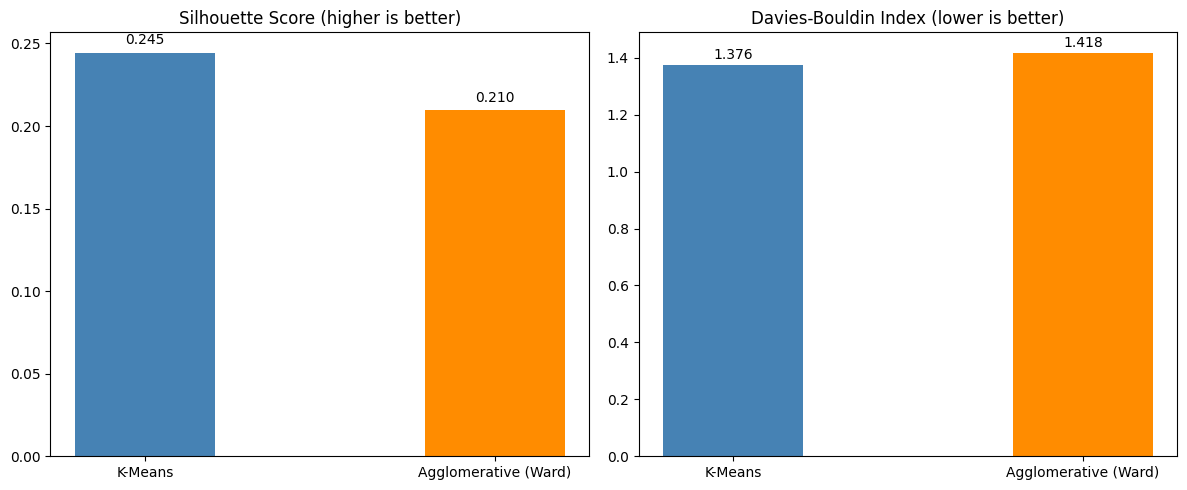

In [1989]:
fig, axes = plt.subplots(1, 2, figsize = (12, 5))

axes[0].bar(clustering_results['Algorithm'], clustering_results['Silhouette Score'], width = 0.4, color = ['steelblue', 'darkorange'])
axes[0].set_title('Silhouette Score (higher is better)')
for index, value in enumerate(clustering_results['Silhouette Score']):     
    axes[0].text(x = index, y = value + 0.005, s = f'{value:.3f}', ha = 'center')

axes[1].bar(clustering_results['Algorithm'], clustering_results['Davies-Bouldin Index'], width = 0.4, color = ['steelblue', 'darkorange'])
axes[1].set_title('Davies-Bouldin Index (lower is better)')
for index, value in enumerate(clustering_results['Davies-Bouldin Index']): 
    axes[1].text(x = index, y = value + 0.02, s = f'{value:.3f}', ha = 'center')

plt.tight_layout()
plt.show()

K-Means is better on both metrics: it has a higher Silhouette Score and a lower Davies-Bouldin Index than Aglomerative Clustering with Ward linkage. The scatter plots of both algorithm shows the similar structure, but K-Means separates the groups more clearly.

The Silhouette score are moderate (about 0.2 - 0.25). This is normal to real behaviour data: the use of the station change gradualy (there is no clear border between a "busy" and a "very busy" station), so the clusters overlap a little. However, the groups are still clearly diferent in their average values, as can see below.

In [1990]:
## Interpretation of the clusters

In [1991]:
cluster_profile = centroids.copy()

sizes = []
for k in range(best_k):
    sizes.append(sum(y_kmeans == k))
cluster_profile['N_PROFILES'] = sizes

cluster_profile

,AVG_OCCUPANCY,OCCUPANCY_STD,AVG_ACTIVITY,BIKE_STANDS,DIST_CENTRE_KM,N_PROFILES
KMeans_Cluster,,,,,,
0,0.517966,0.242520,1.168762,26.258370,0.909065,1583
1,0.449406,0.226860,3.351733,34.904762,1.359275,441
2,0.189489,0.140923,0.848099,34.955133,1.338038,1471
3,0.438769,0.214440,0.948525,36.331665,2.327661,799


In [1992]:
cluster_names = {}
remaining = cluster_profile.copy()

hub = remaining.sort_values('AVG_ACTIVITY').index[-1]
cluster_names[hub] = 'High-turnover hubs'
remaining = remaining.drop(hub)

empty = remaining.sort_values('AVG_OCCUPANCY').index[0]
cluster_names[empty] = 'Bike-depleted stations'
remaining = remaining.drop(empty)

peripheral = remaining.sort_values('DIST_CENTRE_KM').index[-1]
cluster_names[peripheral] = 'Peripheral stations'
remaining = remaining.drop(peripheral)

cluster_names[remaining.index[0]] = 'Compact city-centre stations'

profiles['Segment'] = profiles['KMeans_Cluster'].map(cluster_names)
print(cluster_names)

{np.int32(1): 'High-turnover hubs', np.int32(2): 'Bike-depleted stations', np.int32(3): 'Peripheral stations', np.int32(0): 'Compact city-centre stations'}


In [1993]:
# Percentage of weekend profile in each segment
profiles.groupby('Segment')['IS_WEEKEND'].mean() * 100

Segment
Bike-depleted stations          56.424201
Compact city-centre stations    52.116235
High-turnover hubs              21.541950
Peripheral stations             49.687109
Name: IS_WEEKEND, dtype: float64

In [1994]:
for segment in profiles['Segment'].unique():
    in_segment = (profiles['Segment'] == segment).astype(int)
    top_stations = in_segment.groupby(profiles['NAME']).sum().nlargest(6).index.tolist()
    print(f"{segment}: {top_stations}")

Compact city-centre stations: ['BOLTON STREET', 'CATHAL BRUGHA STREET', 'CHRISTCHURCH PLACE', 'DAME STREET', 'DEVERELL PLACE', 'GEORGES QUAY']
High-turnover hubs: ['GRAND CANAL DOCK', 'MOUNTJOY SQUARE WEST', "SIR PATRICK DUN'S", 'NEW CENTRAL BANK', 'THE POINT', 'HANOVER QUAY']
Bike-depleted stations: ['BROADSTONE', 'FITZWILLIAM SQUARE EAST', 'GRANGEGORMAN LOWER (CENTRAL)', 'GRANGEGORMAN LOWER (NORTH)', 'GRANGEGORMAN LOWER (SOUTH)', 'HARDWICKE PLACE']
Peripheral stations: ['EMMET ROAD', 'HEUSTON STATION (CAR PARK)', 'MOUNT BROWN', 'BROOKFIELD ROAD', 'KILMAINHAM GAOL', 'KILMAINHAM LANE']


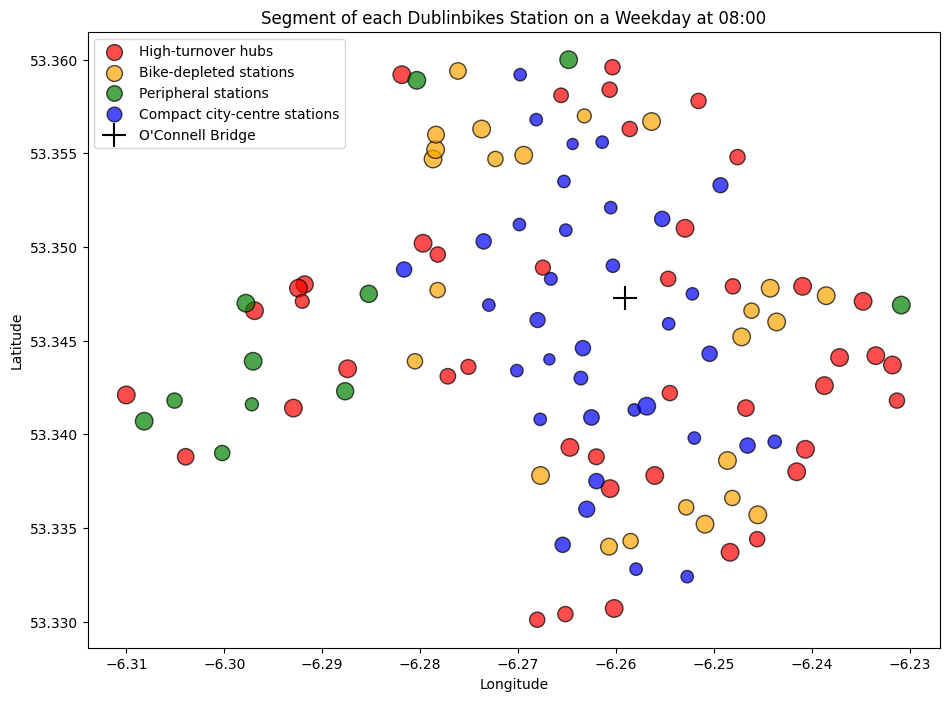

In [1995]:
morning_peak = profiles[(profiles['HOUR'] == 8) & (profiles['IS_WEEKEND'] == 0)]

segment_names = ['High-turnover hubs', 'Bike-depleted stations', 'Peripheral stations', 'Compact city-centre stations']
segment_colors = ['red', 'orange', 'green', 'blue']

plt.figure(figsize = (11, 8))

for segment, color in zip(segment_names, segment_colors):
    subset = morning_peak[morning_peak['Segment'] == segment]
    plt.scatter(subset['LONGITUDE'], subset['LATITUDE'], c = color, s = subset['BIKE_STANDS'] * 4,
                alpha = 0.7, edgecolors = 'black', label = segment)

plt.scatter(centre_lon, centre_lat, c = 'black', marker = '+', s = 300, label = "O'Connell Bridge")

plt.title('Segment of each Dublinbikes Station on a Weekday at 08:00')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend(loc = 'best')
plt.show()

### Interpretation of the four segments

| Segment | Characteristics | Typical stations | What the operator can do |
|---|---|---|---|
| **High-turnover hubs** | High activity (about 3 times the average), large station, mostly on **weekdays** | Grand Canal Dock, Sir Patrick Dun's, New Central Bank, The Point, Hanover Quay, Mountjoy Square West | comuter station in the Docklands and the business area, they need **rebalancing first**  08:00 - 09:00 and 17:00 - 18:00, and they could get more stand. |
| **Bike-depleted station** | Low occupancy (only about 19% of the stands there is bike) and low activitty | Broadstone, Hardwicke Place, Fitzwilliam Square East, Grangegorman Lower | in these stations are **often empty**: users arrive and find no bike, so activity stay low, van should **bring bikes** to them. |
| **Peripheral stations** | Furthest from the centre (more than 2 km), large but less use | Heuston Station, Kilmainham, Emmet Road, Mount Brown, Brookfield Road | Outer stations with stable, low demand. low priority for rebalancing; they could be **promoted** to get more users. |
| **Compact city-centre stations** | Small station near the centre, highest occupancy, average activity | Bolton Street, Cathal Brugha Street, Christchurch Place, Dame Street, George's Quay | Central stations with enough bikes and steady use during the day. |

### Which clustering solution do we prefer, and why?
I prefer the **K-Means solution with 4 clusters** because:
1. It has  **best results on both metrics** (higher Silhouete score and lower Davies-Bouldin Index) compared with Aglomerative Clustering.
2. The clusters are **balanced** in size, and each one has a clear **mean to transport** that the operator can using (rebalancing priorities, new stands, promotion).
3. It is **fast and scalable**: can train it again every month with new data, hierarchical clustering become slow and uses a lot of memory when there are more profiles.
4. The dendrogram was still useful to **confirm** that 4 clusters is a natural number for this data.

---

# Part B - Time Series Analysis

## 3. Hourly demand of the Dublinbikes system

To study the demand over time add the activity of all the stations in each hour. The results is an hourly time series of the bikes taken or returned in the whole system in November 2022 (720 hours).

In [1996]:
# Date and hour of each read as text
df['DATE_HOUR'] = df['TIME'].astype(str).str[:13]

# Total activity of the system in each hour
data = df.groupby('DATE_HOUR')['ACTIVITY'].sum().reset_index()
data = data.rename(columns = {'ACTIVITY': 'Activity'})

data['DAY'] = data['DATE_HOUR'].str[8:10].astype(int)
data['HOUR'] = data['DATE_HOUR'].str[11:13].astype(int)

week_ticks = np.arange(0, 720, 168)
week_labels = ['1 Nov', '8 Nov', '15 Nov', '22 Nov', '29 Nov']

data.head()

,DATE_HOUR,Activity,DAY,HOUR
0,2022-11-01 00,38.0,1,0
1,2022-11-01 01,16.0,1,1
2,2022-11-01 02,0.0,1,2
3,2022-11-01 03,0.0,1,3
4,2022-11-01 04,0.0,1,4


In [1997]:
print("Number of hours:", len(data))
print("Average activity per hour:", data['Activity'].mean())
print("Minimum activity per hour:", data['Activity'].min())
print("Maximum activity per hour:", data['Activity'].max())

Number of hours: 720
Average activity per hour: 252.74444444444444
Minimum activity per hour: 0.0
Maximum activity per hour: 859.0


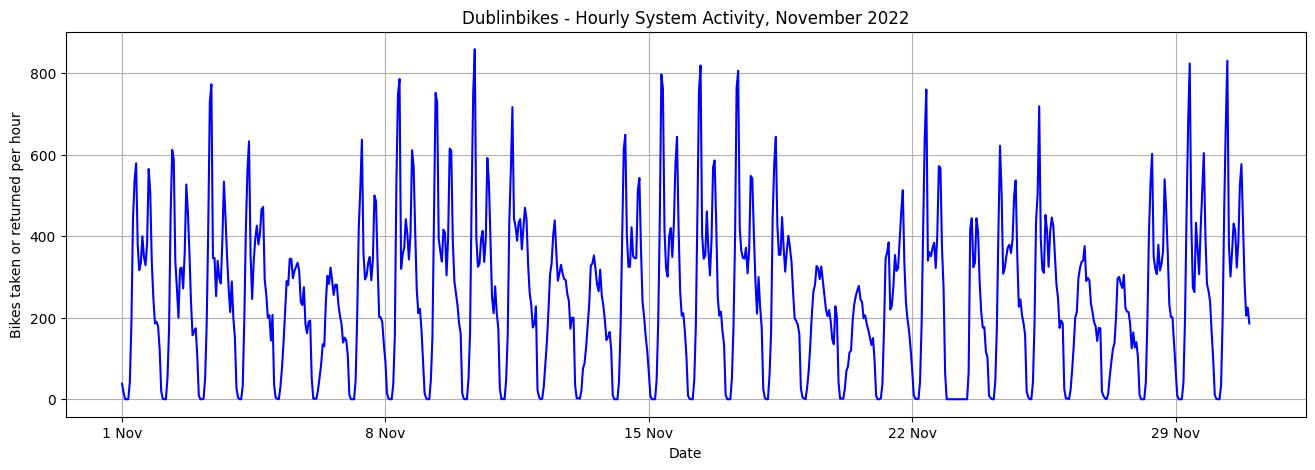

In [1998]:
# Visualize hourly activity in the whole system
plt.figure(figsize = (16, 5))                                      
plt.plot(data.index, data['Activity'], color = 'b')
plt.title('Dublinbikes - Hourly System Activity, November 2022')
plt.ylabel('Bikes taken or returned per hour')
plt.xlabel('Date')
plt.xticks(week_ticks, week_labels)
plt.grid(True)
plt.show()

### Trend, seasonality and anomalies

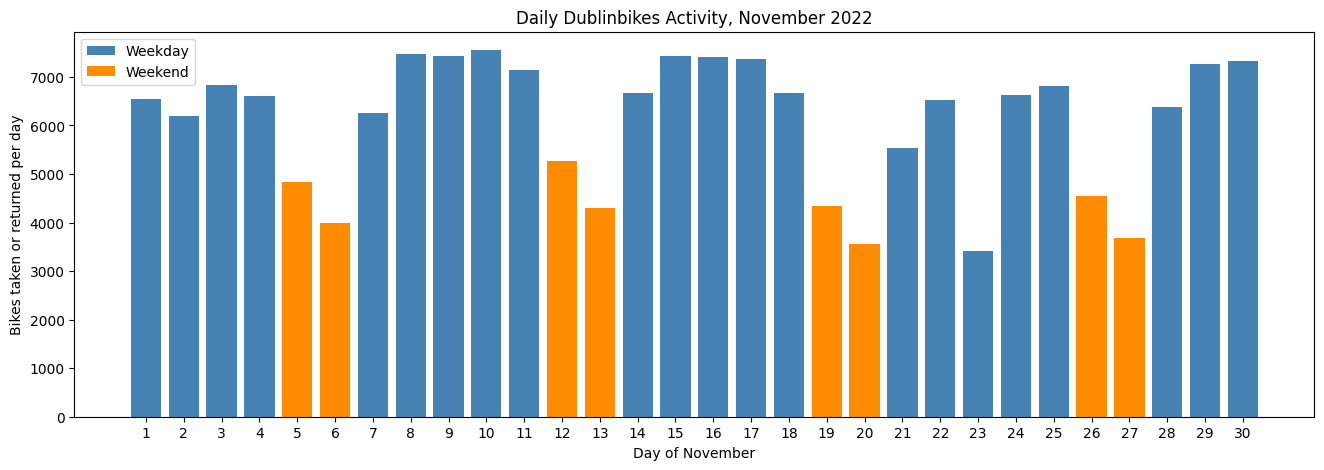

In [1999]:
# Total activity per day
daily = data.groupby('DAY')['Activity'].sum().reset_index()
daily = daily.rename(columns = {'Activity': 'Daily_Activity'})
daily['IS_WEEKEND'] = (daily['DAY'] - (daily['DAY'] / 7).astype(int) * 7 >= 5).astype(int)   # 1 = weekend, 0 = weekday

# Separate weekdays and weekends
weekdays = daily[daily['IS_WEEKEND'] == 0].copy()
weekends = daily[daily['IS_WEEKEND'] == 1].copy()

# Plot the daily totals (weekdays in blue, weekends in orange)
plt.figure(figsize = (16, 5))
plt.bar(weekdays['DAY'], weekdays['Daily_Activity'], color = 'steelblue', label = 'Weekday')
plt.bar(weekends['DAY'], weekends['Daily_Activity'], color = 'darkorange', label = 'Weekend')
plt.title('Daily Dublinbikes Activity, November 2022')
plt.ylabel('Bikes taken or returned per day')
plt.xlabel('Day of November')
plt.xticks(range(1, 31))
plt.legend()
plt.show()

WEEK
1    5893.285714
2    6547.714286
3    6048.142857
4    5423.571429
Name: Daily_Activity, dtype: float64


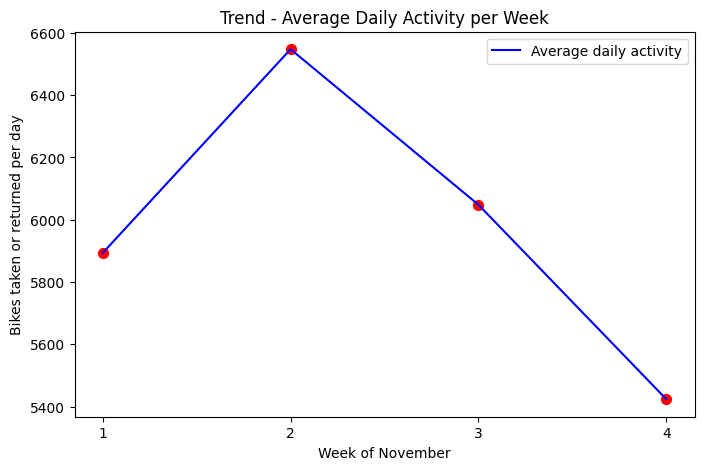

In [2000]:
# Week of each day (week 1 = 1-7 November, ..., week 4 = 22-28 November)
daily['WEEK'] = ((daily['DAY'] - 1) / 7).astype(int) + 1

# Average day activity in each complete week 
weekly = daily[daily['WEEK'] <= 4].groupby('WEEK')['Daily_Activity'].mean()
print(weekly)

plt.figure(figsize = (8, 5))
plt.plot(weekly.index, weekly.values, linestyle = '-', color = 'blue', label = 'Average daily activity')
plt.scatter(weekly.index, weekly.values, color = 'red', marker = 'o', s = 50)
plt.title('Trend - Average Daily Activity per Week')
plt.xlabel('Week of November')
plt.ylabel('Bikes taken or returned per day')
plt.xticks([1, 2, 3, 4])
plt.legend()
plt.show()

In [2001]:

weekday_mean = weekdays['Daily_Activity'].mean()
weekday_std = np.sqrt(np.mean((weekdays['Daily_Activity'] - weekday_mean) * (weekdays['Daily_Activity'] - weekday_mean)))

weekend_mean = weekends['Daily_Activity'].mean()
weekend_std = np.sqrt(np.mean((weekends['Daily_Activity'] - weekend_mean) * (weekends['Daily_Activity'] - weekend_mean)))

weekdays['Z_SCORE'] = (weekdays['Daily_Activity'] - weekday_mean) / weekday_std
weekends['Z_SCORE'] = (weekends['Daily_Activity'] - weekend_mean) / weekend_std

print("Anomalous weekdays:")
print(weekdays[(weekdays['Z_SCORE'] < -2) | (weekdays['Z_SCORE'] > 2)])
print("\nAnomalous weekend days:")
print(weekends[(weekends['Z_SCORE'] < -2) | (weekends['Z_SCORE'] > 2)])

Anomalous weekdays:
    DAY  Daily_Activity  IS_WEEKEND   Z_SCORE
22   23          3415.0           0 -3.733574

Anomalous weekend days:
Empty DataFrame
Columns: [DAY, Daily_Activity, IS_WEEKEND, Z_SCORE]
Index: []


What we learn from the first look at the time series:

- Seasonality: the series have a very strong day seasonality (24 hours): two peak on weekdays (08:00 - 09:00 and 17:00 - 18:00) and almost no activity at night, have also a weekly seasonality: weekends there are much lower total (about 3,500 - 5,300 bikes per day) than during the week (usually about 6,200 - 7,500).

- Trend: there is no strong long-term trend in November, the average day activity goes up from week 1 to week 2 and then get down in weeks 3 and 4. Week 4 is the lowest, partly because of the anomalous days (21 and 23 November) and probably also because of colder and darker days at the end of autumn one month is very short to see a long-term trend or a yearly pattern.

- Anomalies: the z-score test finds an anomaly on Wednesday 23 November 2022 (z-score lower than -3). It is a weekday with about half of the normal demand (about 3,400 bikes, similar to a Sunday). Monday 21 November is also low than a normal weekday, but it is not mark as a anomaly. These drops are probably caused by external factors like bad weather (rain and wind reduce cycling a lot), would need weather data from Met Éireann to confirm this.

## Test the stationarity of the series

We use the Augmented Dickey-Fuller (ADF) test null hypothesis (H0) say that the series has a unit root, which means it is non-stationary. If the p-value is lower than 0.05, we reject H0 and can say that the time series is stationary.

In [2002]:
ad_fuller_result = adfuller(data['Activity'])

print(f'ADF Statistic: {ad_fuller_result[0]}')
print(f'p-value: {ad_fuller_result[1]}')

ADF Statistic: -4.321198404495922
p-value: 0.00040812692401000423


The p-value is low than 0.05 so we reject the null hypothesis the level of the series does not move up or down during the month, so it is stationary (without looking at the seasonality). However, the series clearly has a strong pattern that repeats every 24 hours, and the ADF test does not remove, for deal with this seasonality, apply a seasonal difference of lag 24 (each hour minus the same hour on the day before) and run the ADF test again.

> If your p-value is higher than 0.05, the series is non-stationary and need to use the first difference (d = 1).

In [2003]:
data['Activity Seasonal Difference'] = data['Activity'] - data['Activity'].shift(24)

ad_fuller_result = adfuller(data['Activity Seasonal Difference'].dropna())

print(f'ADF Statistic: {ad_fuller_result[0]}')
print(f'p-value: {ad_fuller_result[1]}')

ADF Statistic: -5.316523334231088
p-value: 5.06021936091234e-06


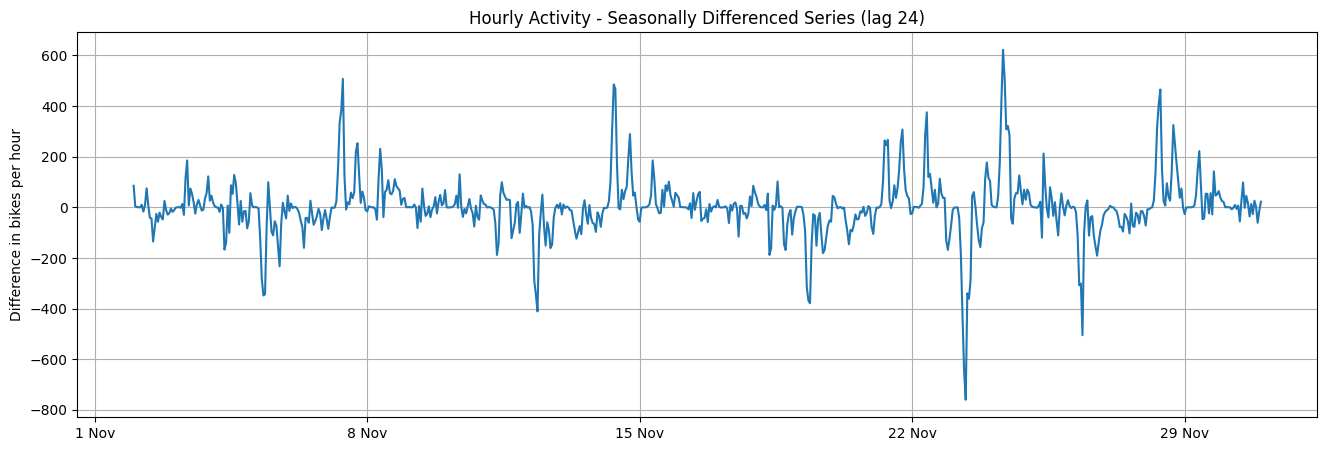

In [2004]:
plt.figure(figsize = [16, 5]); 
data['Activity Seasonal Difference'].plot()
plt.title('Hourly Activity - Seasonally Differenced Series (lag 24)')
plt.ylabel('Difference in bikes per hour')
plt.xticks(week_ticks, week_labels)
plt.grid(True)
plt.show()

## ACF and PACF plots

The ACF shows how much the current value is related to past values, the PACF show the relation with one lag after remove the efect of the shorter lags. use these plots to choose the AR (p) and MA (q) orders and the seasonal orders (P, Q).

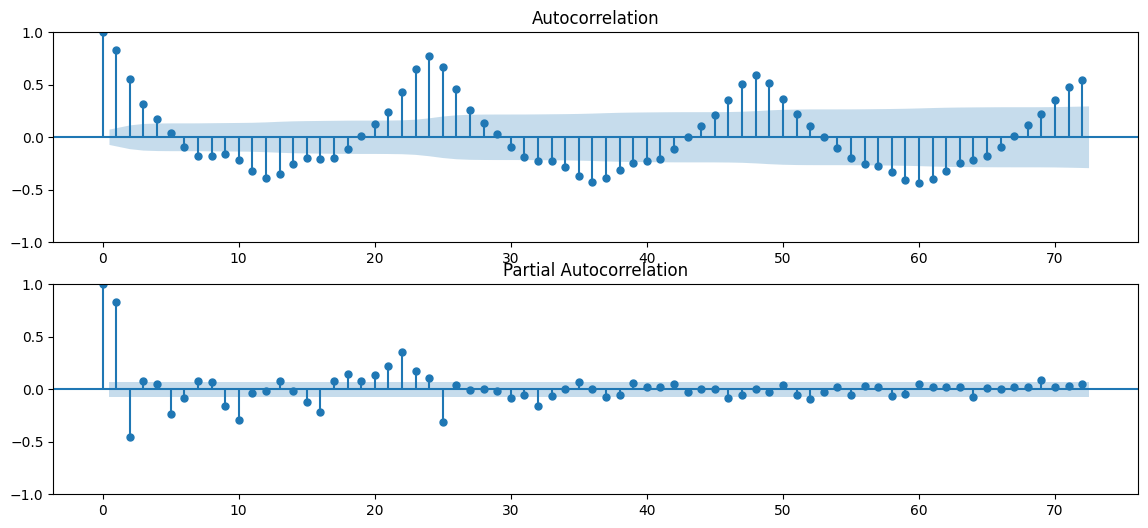

In [2005]:
import statsmodels.api as sm
# ACF and PACF of the original series (72 lags = 3 days)
fig = plt.figure(figsize = (14, 6))
ax1 = fig.add_subplot(211)
fig = sm.graphics.tsa.plot_acf(data['Activity'], lags = 72, ax = ax1)
ax2 = fig.add_subplot(212)
fig = sm.graphics.tsa.plot_pacf(data['Activity'], lags = 72, ax = ax2)
plt.show()

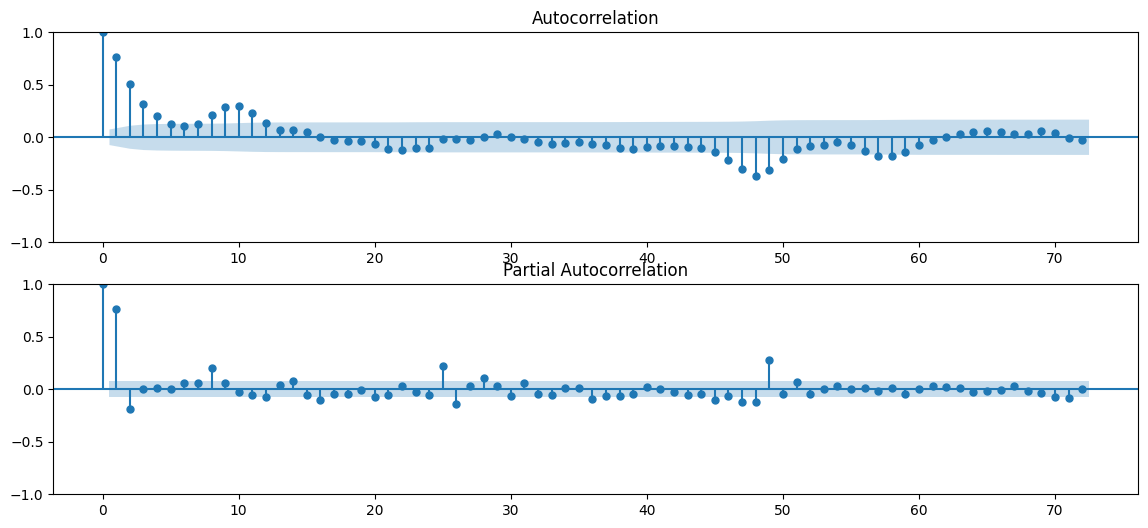

In [2006]:
# ACF and PACF of the seasonally differenced series
fig = plt.figure(figsize = (14, 6))
ax1 = fig.add_subplot(211)
fig = sm.graphics.tsa.plot_acf(data['Activity Seasonal Difference'].dropna(), lags = 72, ax = ax1)
ax2 = fig.add_subplot(212)
fig = sm.graphics.tsa.plot_pacf(data['Activity Seasonal Difference'].dropna(), lags = 72, ax = ax2)
plt.show()

How the plots help us choose the parameters:

- In the original serie the ACF has a wave pattern with peaks at lags 24, 48 and 72, it confirms the daily seasonality (m = 24) and shows that need a seasonal model (SARIMA).

- After the seasonal diference (D = 1), the seasonal waves are smaller the significant spikes at the first lags of the PACF suggest a few AR terms (p), and the spikes around lag 24 suggest seasonal AR/MA terms (P, Q = 0 or 1).

- The plot give a range of values to test, in the final choice of (p, d, q) and (P, D, Q) is made with the AIC (Akaike Information Criterion), which looks at how well the model fits and how complex it is. The lower the AIC, the better.

## Split into training and testing data

keep the last 7 days (168 hours) as the test set, so the models are tested on a full week, includ a weekend. The first 552 hours (23 days) are the training set.

In [2007]:
# Split the data into training and testing
train = data[['Activity']][: -168]
test = data[['Activity']][-168: ]

train.shape, test.shape

((552, 1), (168, 1))

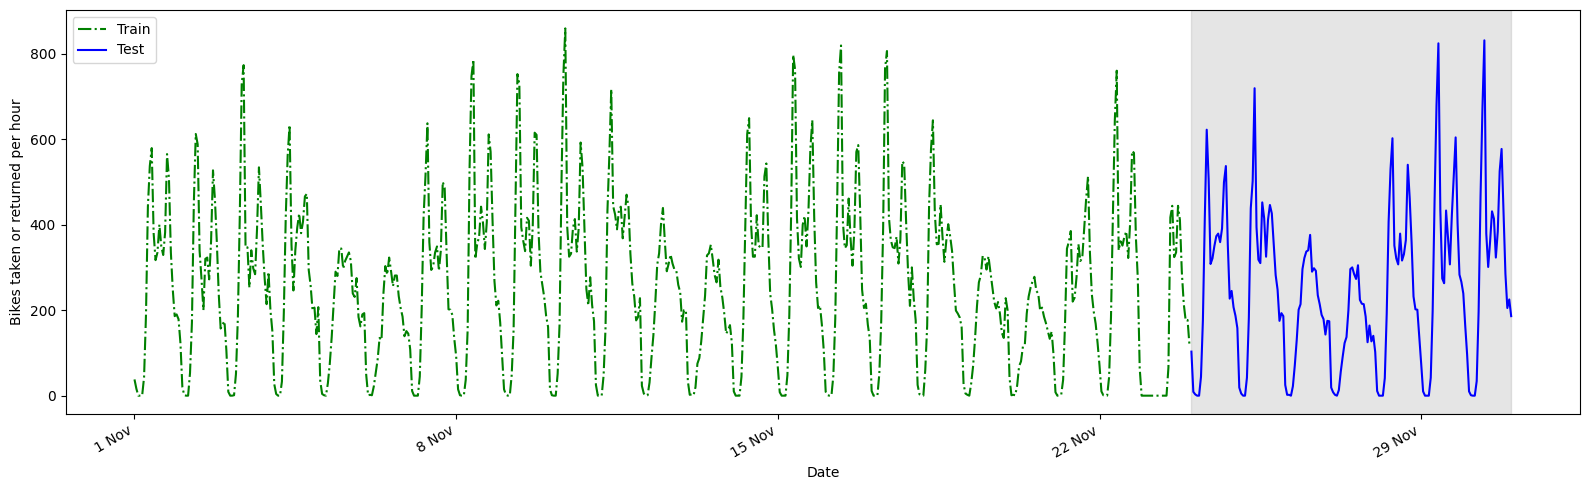

In [2008]:
# Display the training and testing data with matplotlib.pyplot
fig, ax = plt.subplots(figsize = (16, 5))

ax.plot(train.index, train['Activity'], 'g-.', label = 'Train')
ax.plot(test.index, test['Activity'], 'b-', label = 'Test')
ax.set_xlabel('Date')
plt.xticks(week_ticks, week_labels)
ax.set_ylabel('Bikes taken or returned per hour')
ax.axvspan(test.index.min(), test.index.max(), color = '#808080', alpha = 0.2)   # Shade the test period
ax.legend(loc = 2)

fig.autofmt_xdate()
plt.tight_layout()

## Baseline models

A baseline model is a simple solution  problem. It uses simple statistics to make predictions it does not need training and it is easy to build. A good forecasting model must be better than the baselines.

### Mean absolute percentage error (MAPE)

Need an error metric to evaluate forecasts on the test set. Use the mean absolute percenttage error (MAPE). It is easy to understand and it does not depend on the scale of the data.

The Dublinbikes system is closed at night, so between 00:00 and 05:59 the activity is zero or very small. MAPE cannot be calculated when the real value is 0 (we cannot divide by zero), and it becomes very large when the real value is close to 0. For this reason, we calculate the MAPE only for the service hours from 06:00 to 23:59 service_hours). MAE, RMSE and R-squared (Step 17) use all the 168 test hours.

In [2009]:
# Method to calculate the predicted percentage of the dataframe
def mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

service_hours = data['HOUR'][-168:].values >= 6

In [2010]:
# Predict historical mean

In [2011]:
# Calculate the average training data
historical_mean = np.mean(train['Activity'])

# Display the mean value of the training data
historical_mean

np.float64(252.46195652173913)

In [2012]:
# Add a new column named as 'pred_mean' into test dataframe
test.loc[:, 'pred_mean'] = historical_mean

test.head()

,Activity,pred_mean
552,103.0,252.461957
553,9.0,252.461957
554,3.0,252.461957
555,0.0,252.461957
556,0.0,252.461957


In [2013]:
# Calculate the MAPE based on the original and predicted data values (service hours)
mape_hist_mean = mape(test['Activity'][service_hours], test['pred_mean'][service_hours])

mape_hist_mean

np.float64(40.505566573210956)

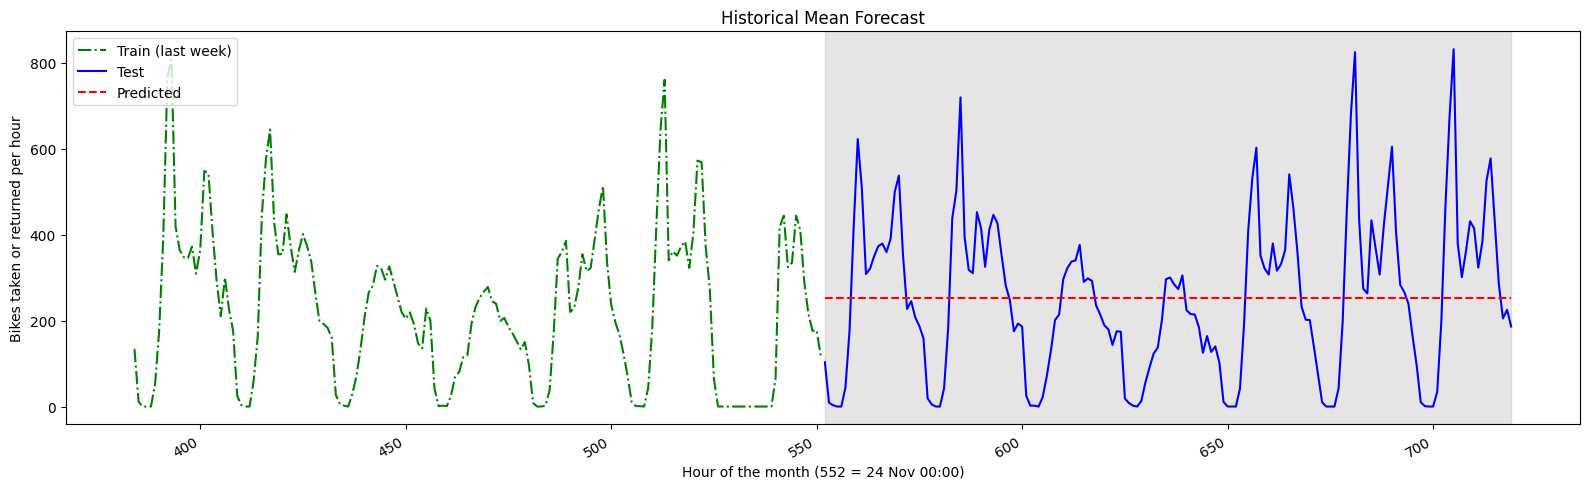

In [2014]:
# Display the last week of training, the testing part and the prediction
fig, ax = plt.subplots(figsize = (16, 5))

ax.plot(train.index[-168:], train['Activity'][-168:], 'g-.', label = 'Train (last week)')
ax.plot(test.index, test['Activity'], 'b-', label = 'Test')
ax.plot(test.index, test['pred_mean'], 'r--', label = 'Predicted')
ax.set_title('Historical Mean Forecast')
ax.set_xlabel('Hour of the month (552 = 24 Nov 00:00)')
ax.set_ylabel('Bikes taken or returned per hour')
ax.axvspan(test.index.min(), test.index.max(), color = '#808080', alpha = 0.2)
ax.legend(loc = 2)

fig.autofmt_xdate()
plt.tight_layout()

# Predict last day mean

We calculate the mean of the last day (24 hours) of the training set use it as the forecast for the whole test week.

In [2015]:
# Predict the last day mean value

last_day_mean = np.mean(train['Activity'][-24:])
last_day_mean

np.float64(142.29166666666666)

In [2016]:
# Add a new column with the last day mean value
test.loc[:, 'pred_last_day_mean'] = last_day_mean

mape_last_day_mean = mape(test['Activity'][service_hours], test['pred_last_day_mean'][service_hours])
mape_last_day_mean

np.float64(51.14988826107813)

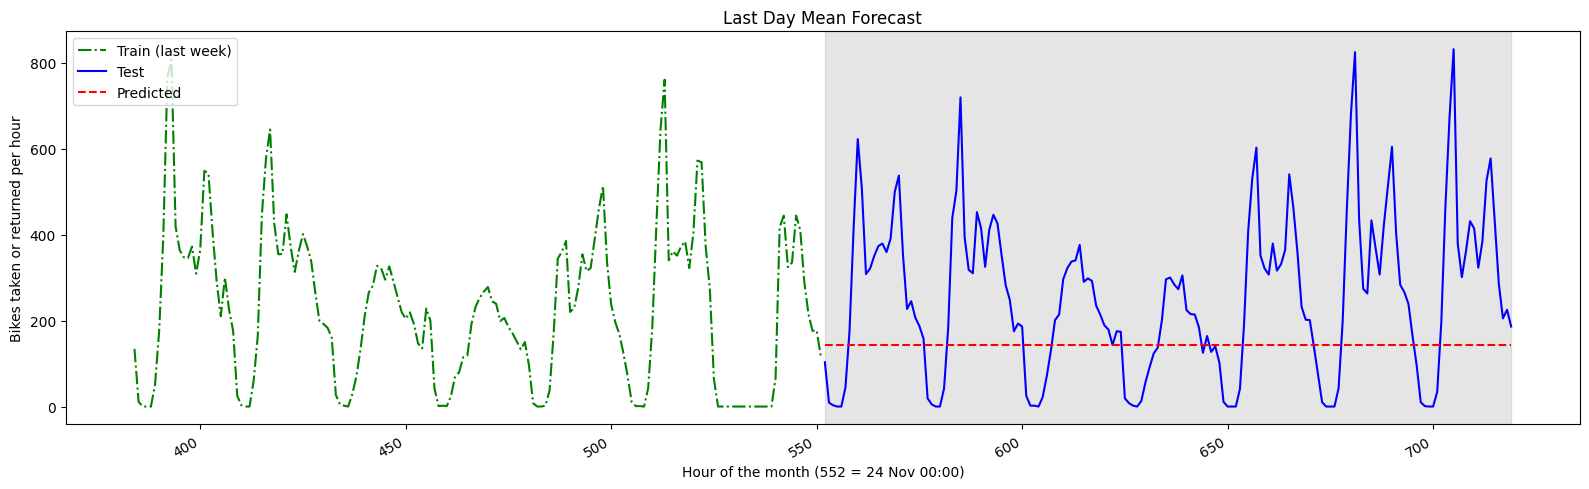

In [2017]:
# Display the last week of training, the testing part and the prediction
fig, ax = plt.subplots(figsize = (16, 5))

ax.plot(train.index[-168:], train['Activity'][-168:], 'g-.', label = 'Train (last week)')
ax.plot(test.index, test['Activity'], 'b-', label = 'Test')
ax.plot(test.index, test['pred_last_day_mean'], 'r--', label = 'Predicted')
ax.set_title('Last Day Mean Forecast')
ax.set_xlabel('Hour of the month (552 = 24 Nov 00:00)')
ax.set_ylabel('Bikes taken or returned per hour')
ax.axvspan(test.index.min(), test.index.max(), color = '#808080', alpha = 0.2)
ax.legend(loc = 2)

fig.autofmt_xdate()
plt.tight_layout()

In [2018]:
# Predict last known value

In [2019]:
last = train['Activity'].iloc[-1]
last

np.float64(117.0)

In [2020]:
test.loc[:, 'pred_last'] = last

# Calculate the MAPE (service hours)
mape_last = mape(test['Activity'][service_hours], test['pred_last'][service_hours])
mape_last

np.float64(58.21786273927817)